# 🛡️ File 5: Evaluasi Out-of-Distribution (OOD) & Metrik Tingkat Lanjut Industri
**Riset Skripsi**: Perbandingan Kinerja RoBERTa-base dan DistilBERT-base untuk Deteksi Phishing URL  
- **Target Runtime**: Google Colab (GPU NVIDIA Tesla T4 16GB / CUDA 12.x)  
- **Storage Backend**: Google Drive (`/content/drive/MyDrive/Skripsi/`)  
- **Tujuan Utama**: Menguji ketahanan generalisasi model (*robustness*) pada dataset phishing eksternal independen (*Out-of-Distribution*) dan menghitung metrik standar industri keamanan siber (TPR pada batas toleransi FPR rendah).

---
### 📋 Ringkasan Alur Kerja Notebook:
1. **Setup Lingkungan & Mount Google Drive**: Menghubungkan Google Drive dan memverifikasi ketersediaan GPU Tesla T4.
2. **Pemuatan Checkpoint Model**:
   - `DistilBERT-base` (dari `/content/drive/MyDrive/Skripsi/models/distilbert_seed42/`).
   - `RoBERTa-base` (dari `/content/drive/MyDrive/Skripsi/models/roberta_phishing/`).
3. **Pemuatan Dataset Eksternal**:
   - Membaca `/content/drive/MyDrive/Skripsi/data/external/phishing_url_dataset_unique.csv` (~48.812 sampel).
   - Preprocessing URL yang konsisten (delimiter spacing untuk WordPiece dan raw URL untuk RoBERTa BPE).
4. **Evaluasi Metrik Standar & Lanjutan**:
   - Accuracy, Precision, Recall, F1-Binary, F1-Macro, ROC-AUC, PR-AUC.
   - **Metrik Industri Khusus**: TPR pada batas FPR ≤ 0.1% dan FPR ≤ 1.0% menggunakan interpolasi kurva ROC.
5. **Visualisasi Publikasi 300 DPI (7 Plot Lengkap)**:
   - `01_confusion_matrices.png`: Confusion Matrix berdampingan (angka & persentase).
   - `02_performance_metrics_bars.png`: Bar chart 7 metrik performa komparatif.
   - `03_roc_and_pr_curves.png`: Kurva ROC dan Precision-Recall kedua model berdampingan.
   - `04_tpr_at_low_fpr_bars.png`: Bar chart deteksi phishing pada toleransi FPR ketat (≤0.1% dan ≤1%).
   - `05_confidence_distribution.png`: Histogram distribusi probabilitas prediksi (log-scale).
   - `06_efficiency_comparison.png`: Bar chart Latensi (ms), Throughput (sampel/s), dan Peak VRAM.
   - `07_tradeoff_bubble_plot.png`: Scatter plot Latensi vs F1-Score (ukuran gelembung = jumlah parameter).
6. **Error Analysis**: Ekstraksi 5 sampel URL False Positive dan 5 False Negative dengan probabilitasnya.
7. **Append Logbook**: Menambahkan ringkasan tabel evaluasi ke `/content/drive/MyDrive/Skripsi/SKRIPSI_LOG.md`.


## 1. Setup Lingkungan & Instalasi Dependensi
Menginstalasi modul evaluasi deep learning: `transformers`, `tokenizers`, `torch`, `scipy`, `scikit-learn`, `pandas`, `numpy`, `matplotlib`, `seaborn`.


In [1]:
# Instalasi library di Google Colab
!pip install transformers tokenizers torch scipy scikit-learn pandas numpy tqdm matplotlib seaborn -q

import os
import sys
import gc
import time
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import interpolate

import torch
from torch.utils.data import Dataset, DataLoader
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DistilBertForSequenceClassification,
    RobertaForSequenceClassification
)
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    roc_curve, precision_recall_curve
)
from google.colab import drive

# Setup Hardware Device
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(f"Device Operasi  : {device}")
if torch.cuda.is_available():
    print(f"GPU Hardware    : {torch.cuda.get_device_name(0)}")
    print(f"VRAM Capacity   : {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")

# Setup Gaya Grafik
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 300
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

print("[OK] Seluruh library berhasil diimpor.")


Device Operasi  : cuda:0
GPU Hardware    : NVIDIA A100-SXM4-40GB
VRAM Capacity   : 39.49 GB
[OK] Seluruh library berhasil diimpor.


## 2. Mount Google Drive & Konfigurasi Path
Menghubungkan direktori Google Drive dan memverifikasi ketersediaan checkpoint model dan dataset eksternal.


In [2]:
# 1. Mount Google Drive
print("[INFO] Mounting Google Drive...")
drive.mount('/content/drive')

# 2. Direktori Proyek
BASE_DIR = "/content/drive/MyDrive/Skripsi"
MODELS_DIR = os.path.join(BASE_DIR, "models")
RESULTS_DIR = os.path.join(BASE_DIR, "results")
os.makedirs(RESULTS_DIR, exist_ok=True)

# 3. Path Model Checkpoints
DISTILBERT_DIR = os.path.join(MODELS_DIR, "distilbert_seed42")
ROBERTA_DIR = os.path.join(MODELS_DIR, "roberta_phishing")

# 4. Path Dataset Eksternal
EXTERNAL_CSV_PRIMARY = os.path.join(BASE_DIR, "data", "external", "phishing_url_dataset_unique.csv")
EXTERNAL_CSV_ALT = os.path.join(BASE_DIR, "new data", "external", "phishing_url_dataset_unique.csv")

# 5. File Log Skripsi
LOG_FILE = os.path.join(BASE_DIR, "SKRIPSI_LOG.md")

# Verifikasi Keberadaan Artefak
for name, path in [('DistilBERT Checkpoint', DISTILBERT_DIR), ('RoBERTa Checkpoint', ROBERTA_DIR)]:
    if not os.path.exists(path):
        raise FileNotFoundError(f"❌ Checkpoint {name} tidak ditemukan di: {path}. Jalankan 03_Train_Transformers.ipynb!")
    print(f"✅ {name} siap: {os.listdir(path)[:4]}")

ext_csv_path = None
for p in [EXTERNAL_CSV_PRIMARY, EXTERNAL_CSV_ALT]:
    if os.path.exists(p):
        ext_csv_path = p
        break

if ext_csv_path is None:
    raise FileNotFoundError(
        f"❌ File dataset eksternal tidak ditemukan!\n"
        f"Harap pastikan file berada di: {EXTERNAL_CSV_PRIMARY}"
    )

print(f"✅ Dataset Eksternal ditemukan: {ext_csv_path}")


Mounted at /content/drive
✅ DistilBERT Checkpoint siap: ['config.json', 'model.safetensors', 'tokenizer_config.json', 'tokenizer.json']
✅ RoBERTa Checkpoint siap: ['config.json', 'model.safetensors', 'tokenizer_config.json', 'tokenizer.json']
✅ Dataset Eksternal ditemukan: /content/drive/MyDrive/Skripsi/data/external/phishing_url_dataset_unique.csv


## 3. Pemuatan & Preprocessing Dataset Eksternal OOD
Memuat dataset phishing eksternal independen, mendeteksi nama kolom secara otomatis, memetakan label biner (0 = Benign, 1 = Phishing), serta menerapkan preprocessing delimiter-spacing.


In [3]:
print(f"[INFO] Membaca dataset eksternal dari: {ext_csv_path}...")
raw_ext_df = pd.read_csv(ext_csv_path)
print(f"Total baris mentah: {len(raw_ext_df):,} | Kolom: {raw_ext_df.columns.tolist()}")

# 1. Deteksi otomatis kolom URL dan Label
col_map = {c.lower().strip(): c for c in raw_ext_df.columns}
url_col = next((col_map[k] for k in ['url', 'urls', 'link', 'domain', 'website', 'text'] if k in col_map), raw_ext_df.columns[0])
label_col = next((col_map[k] for k in ['label', 'labels', 'status', 'type', 'class', 'target', 'result', 'phishing'] if k in col_map), raw_ext_df.columns[1])
print(f"[INFO] Terdeteksi -> Kolom URL: '{url_col}' | Kolom Label: '{label_col}'")

ext_df = raw_ext_df[[url_col, label_col]].copy()
ext_df.columns = ['url', 'label']
ext_df = ext_df.dropna(subset=['url', 'label']).reset_index(drop=True)

# 2. Standarisasi Label ke Integer Biner (0 = Benign, 1 = Phishing)
if ext_df['label'].dtype == object or str(ext_df['label'].dtype) == 'category':
    label_map = {
        'benign': 0, 'legitimate': 0, 'good': 0, 'safe': 0, 'normal': 0, '0': 0, 'false': 0, '-1': 0,
        'phishing': 1, 'malicious': 1, 'bad': 1, 'unsafe': 1, 'defacement': 1, 'malware': 1, 'spam': 1, '1': 1, 'true': 1
    }
    ext_df['label'] = ext_df['label'].astype(str).str.lower().str.strip().map(label_map)

ext_df['label'] = pd.to_numeric(ext_df['label'], errors='coerce')
ext_df = ext_df.dropna(subset=['label']).reset_index(drop=True)
ext_df['label'] = ext_df['label'].astype(int)

# 3. Preprocessing URL (normalisasi & delimiter-spacing)
def normalize_url(u: str) -> str:
    if not isinstance(u, str):
        return ""
    u = u.strip().lower()
    u = re.sub(r'^[a-z]+://', '', u)
    u = re.sub(r'^www\d*\.', '', u)
    u = re.sub(r'/+$', '', u)
    return u.strip()

def preprocess_delimiter_spacing(u: str) -> str:
    if not isinstance(u, str):
        return ""
    u = u.strip()
    u = u.replace('://', ' :// ')
    u = u.replace('/', ' / ')
    u = u.replace('?', ' ? ')
    u = u.replace('=', ' = ')
    u = u.replace('&', ' & ')
    u = u.replace('.', ' . ')
    u = u.replace('-', ' - ')
    return re.sub(r'\s+', ' ', u).strip()

ext_df['url_norm'] = ext_df['url'].apply(normalize_url)
ext_df = ext_df[ext_df['url_norm'] != ''].reset_index(drop=True)
ext_df['url_spaced'] = ext_df['url_norm'].apply(preprocess_delimiter_spacing)

print(f"\n[OK] Dataset eksternal bersih siap uji: {len(ext_df):,} sampel")
print("Distribusi Kelas:")
print(ext_df['label'].value_counts())
print(ext_df['label'].value_counts(normalize=True).apply(lambda x: f"{x*100:.2f}%"))


[INFO] Membaca dataset eksternal dari: /content/drive/MyDrive/Skripsi/data/external/phishing_url_dataset_unique.csv...
Total baris mentah: 48,812 | Kolom: ['url', 'label', 'source']
[INFO] Terdeteksi -> Kolom URL: 'url' | Kolom Label: 'label'

[OK] Dataset eksternal bersih siap uji: 48,812 sampel
Distribusi Kelas:
label
1    24406
0    24406
Name: count, dtype: int64
label
1    50.00%
0    50.00%
Name: proportion, dtype: object


## 4. Dataset Loader & Benchmark Inferensi Modular
Menguji inferensi model secara murni tanpa gradien (`torch.no_grad()`) dengan Mixed Precision FP16 untuk mengukur waktu inferensi, latensi per URL, throughput, dan peak VRAM.


In [4]:
class EvalURLDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_length=128):
        self.texts = list(texts)
        self.labels = list(labels)
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        text = str(self.texts[idx])
        label = self.labels[idx]
        encoding = self.tokenizer(
            text,
            truncation=True,
            padding='max_length',
            max_length=self.max_length,
            return_tensors='pt'
        )
        return {
            'input_ids': encoding['input_ids'].squeeze(0),
            'attention_mask': encoding['attention_mask'].squeeze(0),
            'labels': torch.tensor(label, dtype=torch.long)
        }

def evaluate_model_pipeline(model, tokenizer, texts, labels, model_label="Model", batch_size=64):
    print(f"\n======================================================================")
    print(f"🔍 Evaluasi OOD: {model_label} ({len(texts):,} sampel)...")
    print(f"======================================================================")

    dataset = EvalURLDataset(texts, labels, tokenizer)
    dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)

    model.eval()
    model.to(device)
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()

    all_preds = []
    all_labels = []
    all_probs = []

    # Warmup
    with torch.no_grad():
        for b in dataloader:
            _ = model(b['input_ids'][:4].to(device), b['attention_mask'][:4].to(device))
            break

    t_start = time.perf_counter()
    use_amp = torch.cuda.is_available()

    with torch.no_grad():
        for batch in dataloader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            lbls = batch['labels'].to(device)

            with torch.cuda.amp.autocast(enabled=use_amp):
                outputs = model(input_ids=input_ids, attention_mask=attention_mask)

            logits = outputs.logits
            probs = torch.softmax(logits, dim=-1)
            preds = torch.argmax(logits, dim=-1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(lbls.cpu().numpy())
            all_probs.extend(probs[:, 1].cpu().numpy())

    total_time = time.perf_counter() - t_start
    peak_vram = torch.cuda.max_memory_allocated() / (1024**3) if torch.cuda.is_available() else 0.0

    all_labels = np.array(all_labels)
    all_preds = np.array(all_preds)
    all_probs = np.array(all_probs)

    num_samples = len(all_labels)
    latency_ms = (total_time / num_samples) * 1000.0
    throughput = num_samples / total_time
    total_params = sum(p.numel() for p in model.parameters())

    # Metrik Klasifikasi
    acc = accuracy_score(all_labels, all_preds)
    prec = precision_score(all_labels, all_preds, zero_division=0)
    rec = recall_score(all_labels, all_preds, zero_division=0)
    f1_bin = f1_score(all_labels, all_preds, average='binary', zero_division=0)
    f1_mac = f1_score(all_labels, all_preds, average='macro', zero_division=0)
    roc_auc = roc_auc_score(all_labels, all_probs)
    pr_auc = average_precision_score(all_labels, all_probs)
    cm = confusion_matrix(all_labels, all_preds)

    # METRIK KHUSUS INDUSTRI: TPR at low FPR (<= 0.1% dan <= 1.0%)
    fpr, tpr, thresholds = roc_curve(all_labels, all_probs)
    interp_tpr = interpolate.interp1d(fpr, tpr, bounds_error=False, fill_value=(0.0, 1.0))
    tpr_at_01_fpr = float(interp_tpr(0.001)) # FPR <= 0.1%
    tpr_at_1_fpr = float(interp_tpr(0.010))  # FPR <= 1.0%

    metrics = {
        'model': model_label,
        'accuracy': round(acc, 4),
        'precision': round(prec, 4),
        'recall': round(rec, 4),
        'f1_binary': round(f1_bin, 4),
        'f1_macro': round(f1_mac, 4),
        'roc_auc': round(roc_auc, 4),
        'pr_auc': round(pr_auc, 4),
        'tpr_at_fpr_0.1pct': round(tpr_at_01_fpr, 4),
        'tpr_at_fpr_1.0pct': round(tpr_at_1_fpr, 4),
        'latency_ms': round(latency_ms, 4),
        'throughput_sps': round(throughput, 1),
        'peak_vram_gb': round(peak_vram, 3),
        'total_params': total_params,
        'y_true': all_labels,
        'y_pred': all_preds,
        'y_prob': all_probs,
        'confusion_matrix': cm
    }

    print(f"Accuracy         : {acc*100:.2f}%")
    print(f"Precision        : {prec:.4f}")
    print(f"Recall           : {rec:.4f}")
    print(f"F1-Score (Binary): {f1_bin:.4f}")
    print(f"F1-Score (Macro) : {f1_mac:.4f}")
    print(f"ROC-AUC          : {roc_auc:.4f}")
    print(f"PR-AUC           : {pr_auc:.4f}")
    print(f"TPR @ FPR<=0.1%  : {tpr_at_01_fpr*100:.2f}%")
    print(f"TPR @ FPR<=1.0%  : {tpr_at_1_fpr*100:.2f}%")
    print(f"Latency          : {latency_ms:.4f} ms/sampel")
    print(f"Throughput       : {throughput:,.1f} sampel/detik")
    print(f"Peak VRAM        : {peak_vram:.3f} GB")

    return metrics

print("[OK] Pipeline evaluasi model siap.")


[OK] Pipeline evaluasi model siap.


## 5. Eksekusi Evaluasi Model DistilBERT & RoBERTa pada Dataset Eksternal
Memuat checkpoint masing-masing arsitektur dan mengeksekusi evaluasi performa.


In [5]:
# 1. Evaluasi DistilBERT-base
distil_tokenizer = AutoTokenizer.from_pretrained(DISTILBERT_DIR)
distil_model = AutoModelForSequenceClassification.from_pretrained(DISTILBERT_DIR)

distil_results = evaluate_model_pipeline(
    model=distil_model,
    tokenizer=distil_tokenizer,
    texts=ext_df['url_spaced'],
    labels=ext_df['label'],
    model_label="DistilBERT-base"
)

del distil_model
if torch.cuda.is_available():
    torch.cuda.empty_cache()
gc.collect()

# 2. Evaluasi RoBERTa-base
roberta_tokenizer = AutoTokenizer.from_pretrained(ROBERTA_DIR)
roberta_model = AutoModelForSequenceClassification.from_pretrained(ROBERTA_DIR)

roberta_results = evaluate_model_pipeline(
    model=roberta_model,
    tokenizer=roberta_tokenizer,
    texts=ext_df['url_norm'],
    labels=ext_df['label'],
    model_label="RoBERTa-base"
)

del roberta_model
if torch.cuda.is_available():
    torch.cuda.empty_cache()
gc.collect()

# Susun Tabel Komparasi
models_eval = [distil_results, roberta_results]
comparison_summary = []
for m in models_eval:
    row = {k: v for k, v in m.items() if k not in ['y_true', 'y_pred', 'y_prob', 'confusion_matrix']}
    comparison_summary.append(row)

df_comparison = pd.DataFrame(comparison_summary)
print("\n=== RINGKASAN METRIK EVALUASI EKSTERNAL (OOD) ===")
display(df_comparison)


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]


🔍 Evaluasi OOD: DistilBERT-base (48,812 sampel)...


/tmp/ipykernel_4482/3968173511.py:59: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_amp):


Accuracy         : 60.37%
Precision        : 0.5607
Recall           : 0.9582
F1-Score (Binary): 0.7075
F1-Score (Macro) : 0.5468
ROC-AUC          : 0.8380
PR-AUC           : 0.8218
TPR @ FPR<=0.1%  : 0.92%
TPR @ FPR<=1.0%  : 9.21%
Latency          : 0.1513 ms/sampel
Throughput       : 6,611.3 sampel/detik
Peak VRAM        : 0.508 GB


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]


🔍 Evaluasi OOD: RoBERTa-base (48,812 sampel)...


/tmp/ipykernel_4482/3968173511.py:59: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_amp):


Accuracy         : 68.14%
Precision        : 0.6151
Recall           : 0.9691
F1-Score (Binary): 0.7526
F1-Score (Macro) : 0.6526
ROC-AUC          : 0.9529
PR-AUC           : 0.9535
TPR @ FPR<=0.1%  : 3.84%
TPR @ FPR<=1.0%  : 38.43%
Latency          : 0.2551 ms/sampel
Throughput       : 3,920.6 sampel/detik
Peak VRAM        : 0.829 GB

=== RINGKASAN METRIK EVALUASI EKSTERNAL (OOD) ===


,model,accuracy,precision,recall,f1_binary,f1_macro,roc_auc,pr_auc,tpr_at_fpr_0.1pct,tpr_at_fpr_1.0pct,latency_ms,throughput_sps,peak_vram_gb,total_params
0,DistilBERT-base,0.6037,0.5607,0.9582,0.7075,0.5468,0.8380,0.8218,0.0092,0.0921,0.1513,6611.3,0.508,66839810
1,RoBERTa-base,0.6814,0.6151,0.9691,0.7526,0.6526,0.9529,0.9535,0.0384,0.3843,0.2551,3920.6,0.829,124647170


## 6. Pembuatan 7 Visualisasi Standar Publikasi Skripsi (Resolusi 300 DPI)
Menghasilkan 7 grafik analisis komparatif dan menyimpannya secara otomatis ke `/content/drive/MyDrive/Skripsi/results/`.


[INFO] Membuat 7 visualisasi evaluasi 300 DPI di folder results...


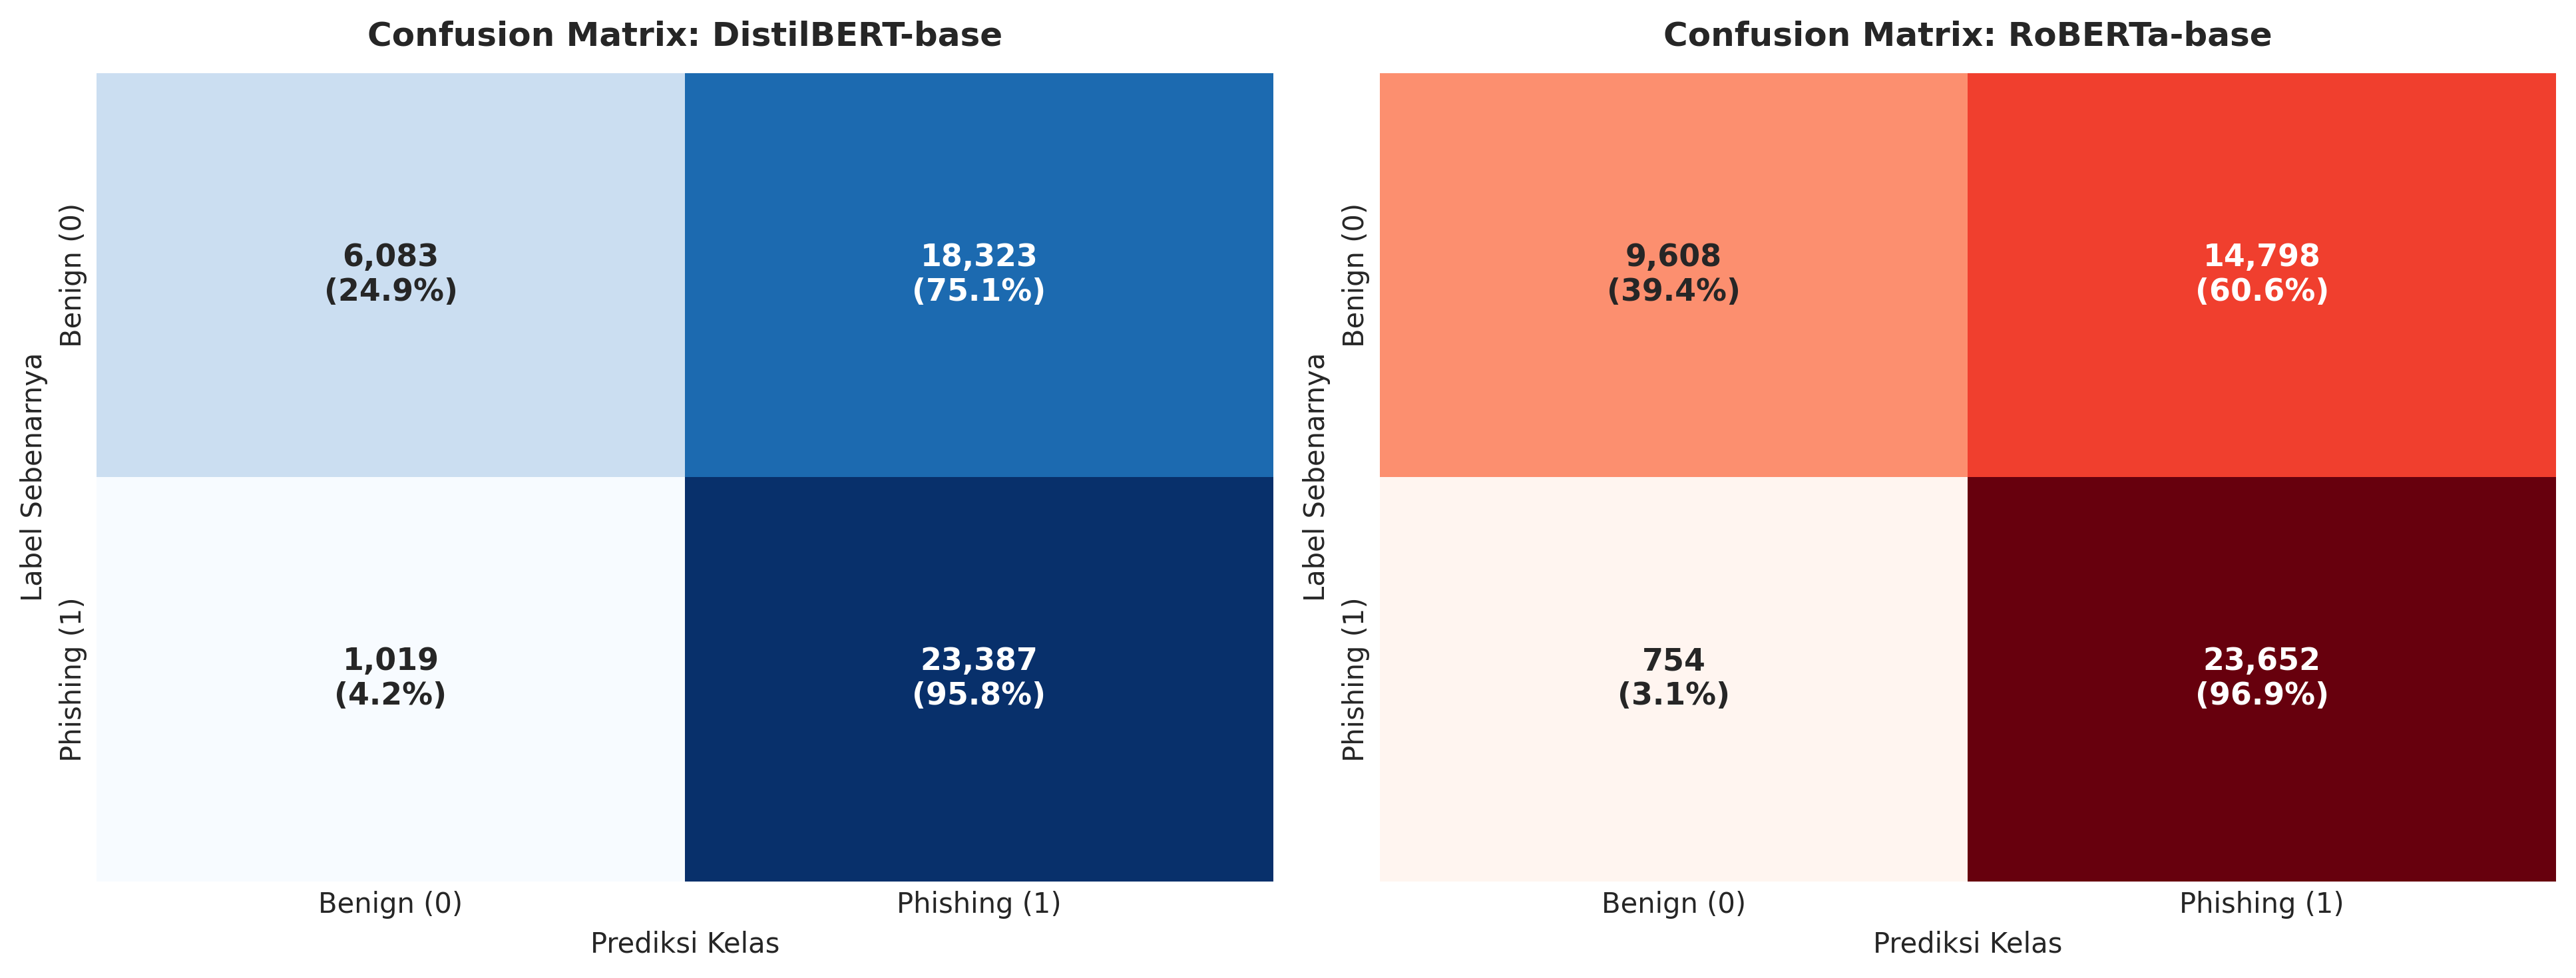

✅ Tersimpan: /content/drive/MyDrive/Skripsi/results/01_confusion_matrices.png


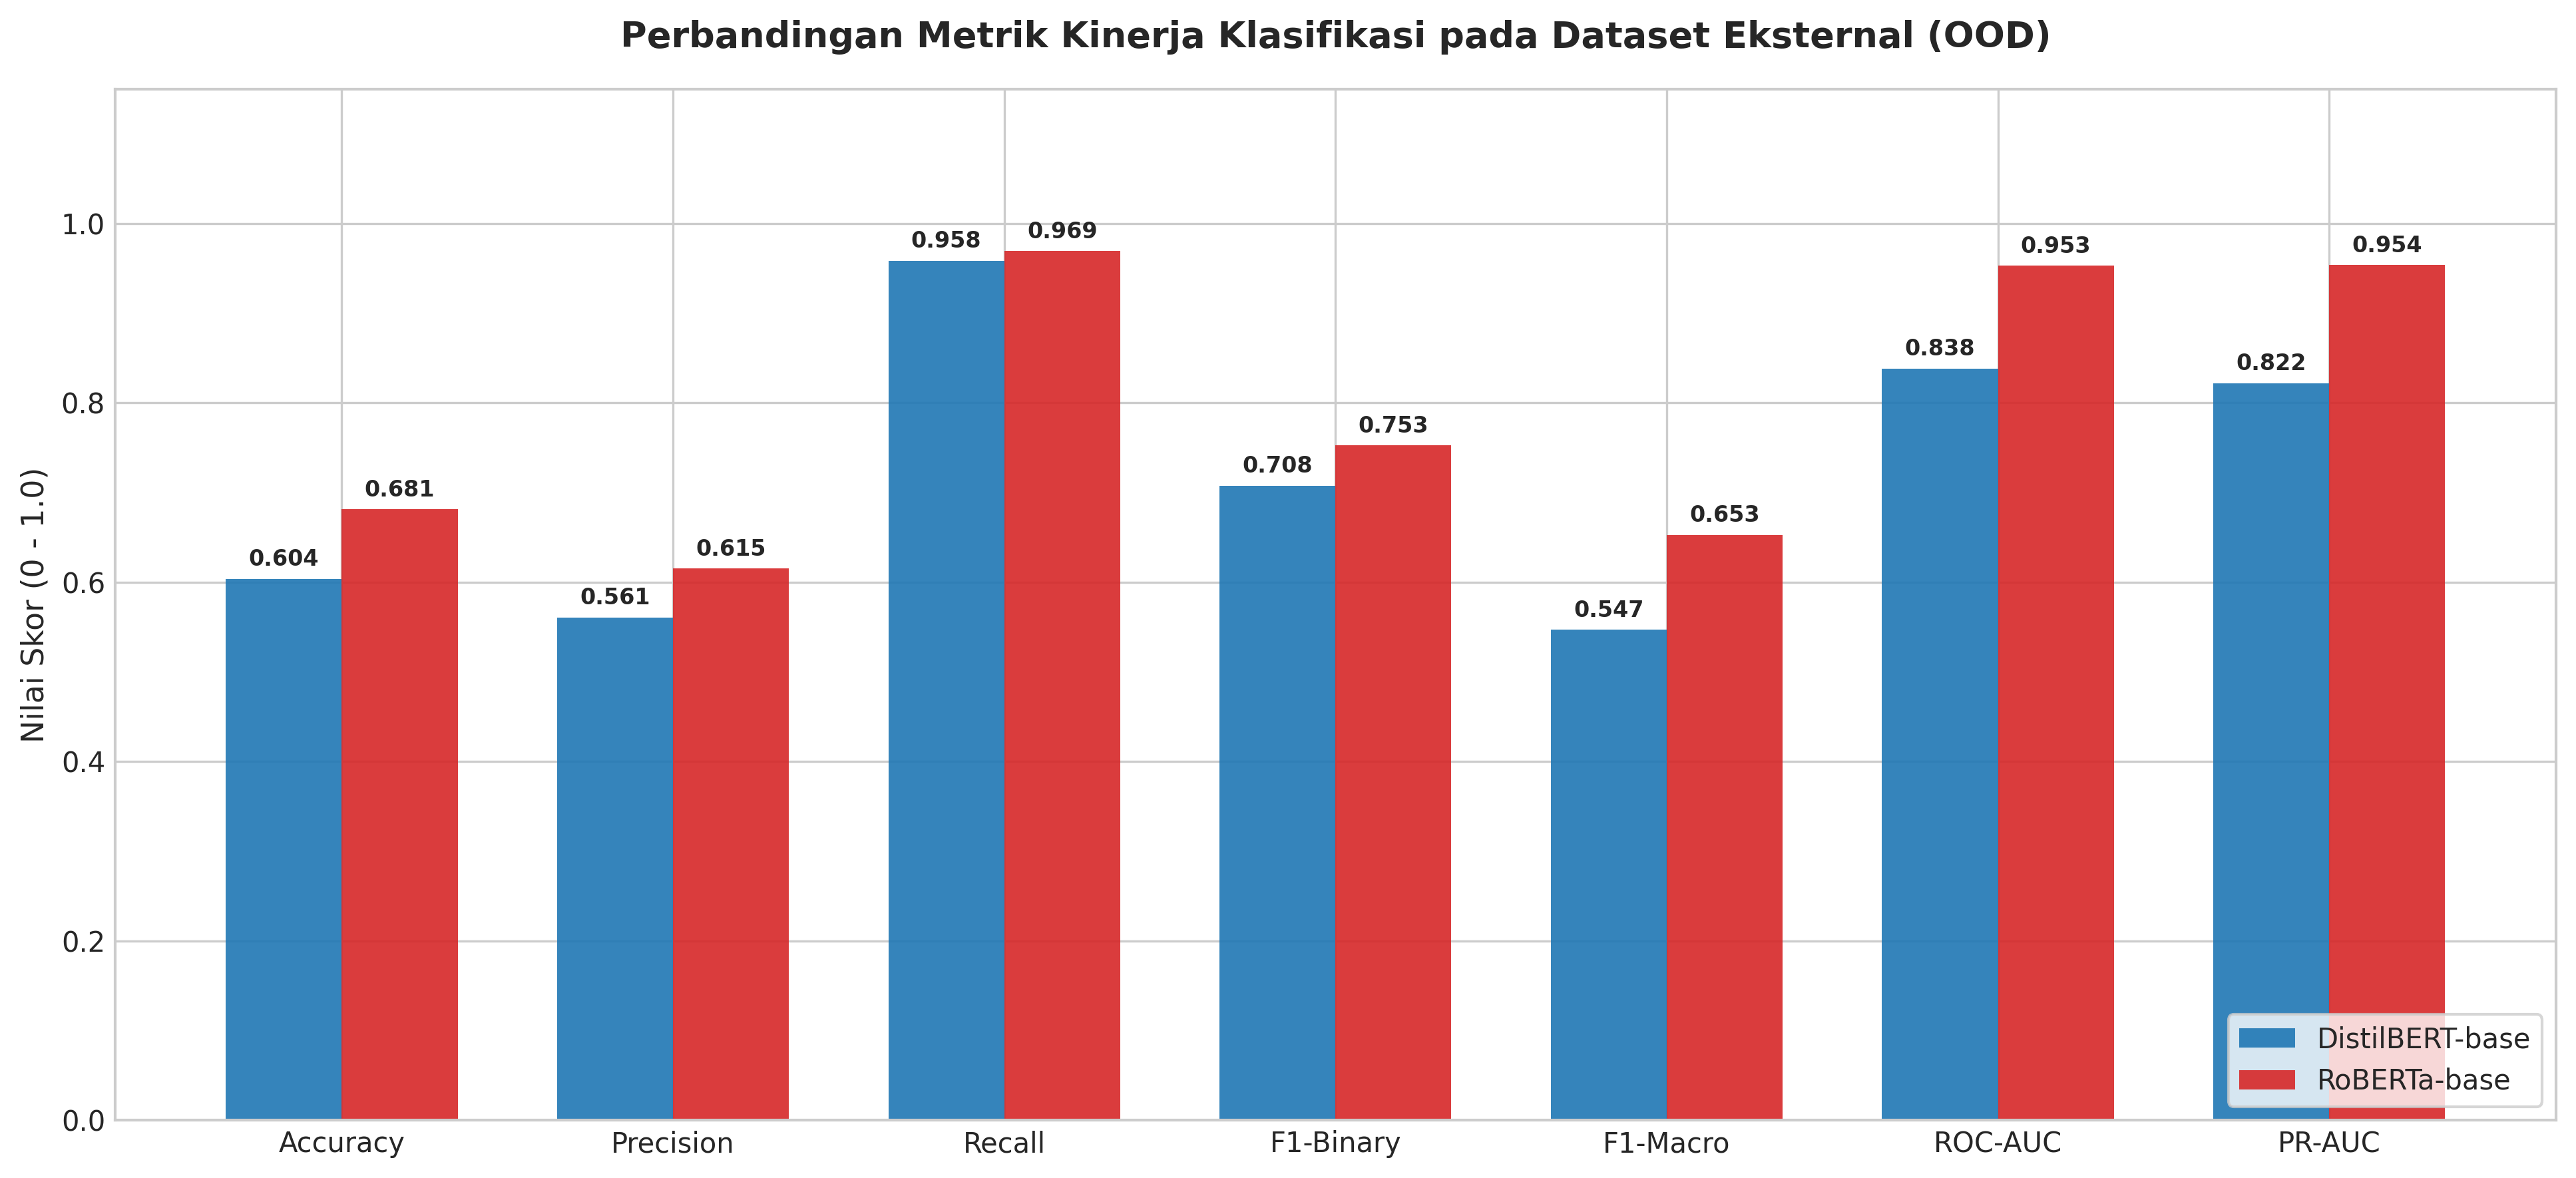

✅ Tersimpan: /content/drive/MyDrive/Skripsi/results/02_performance_metrics_bars.png


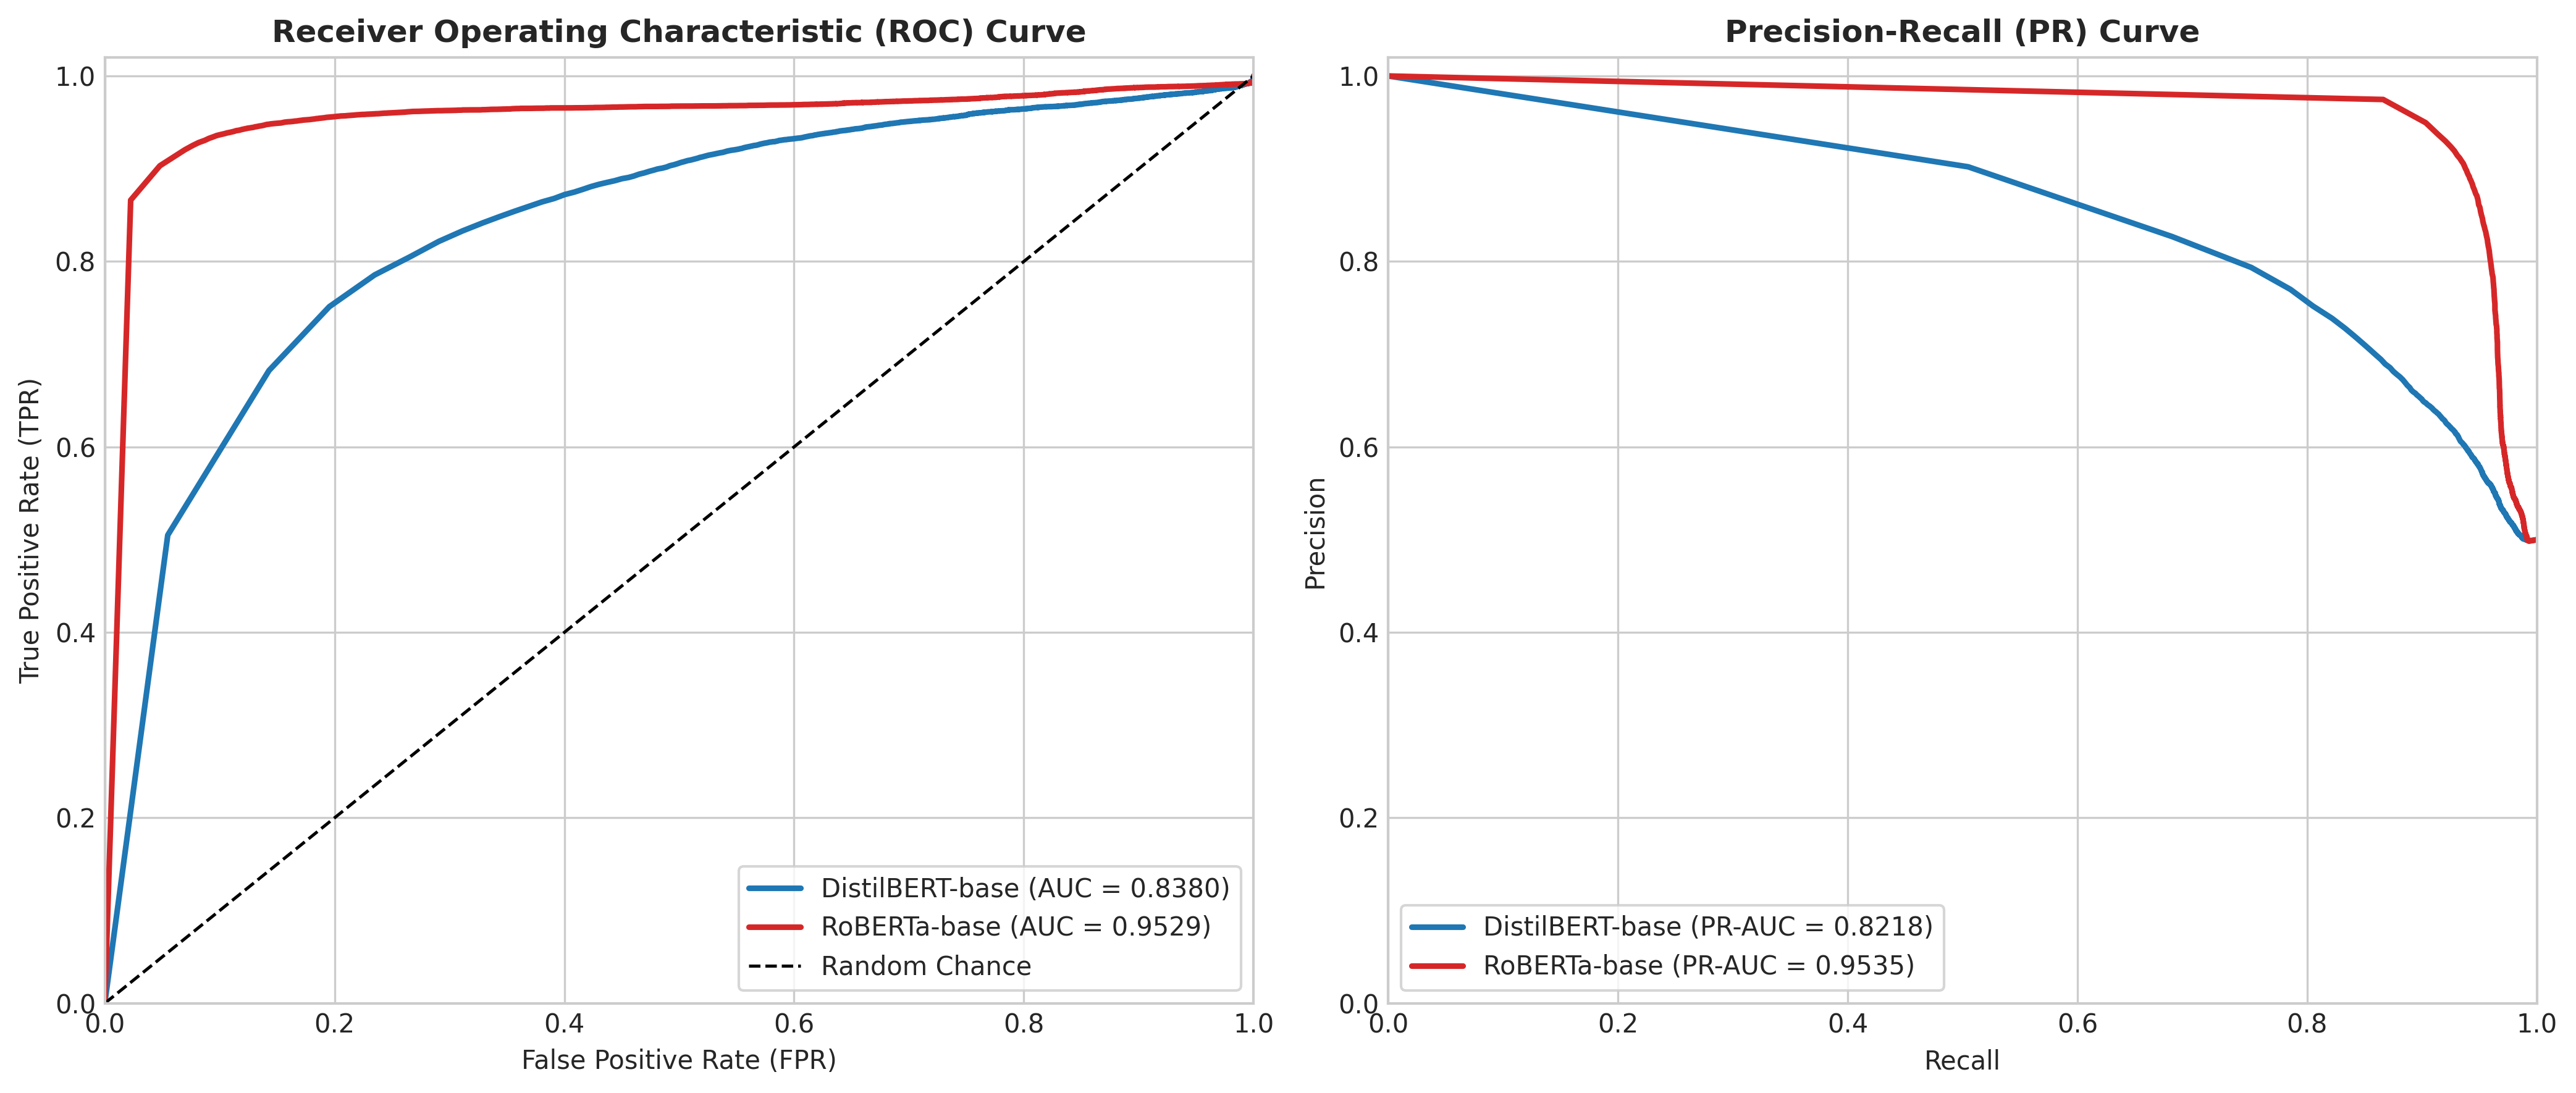

✅ Tersimpan: /content/drive/MyDrive/Skripsi/results/03_roc_and_pr_curves.png


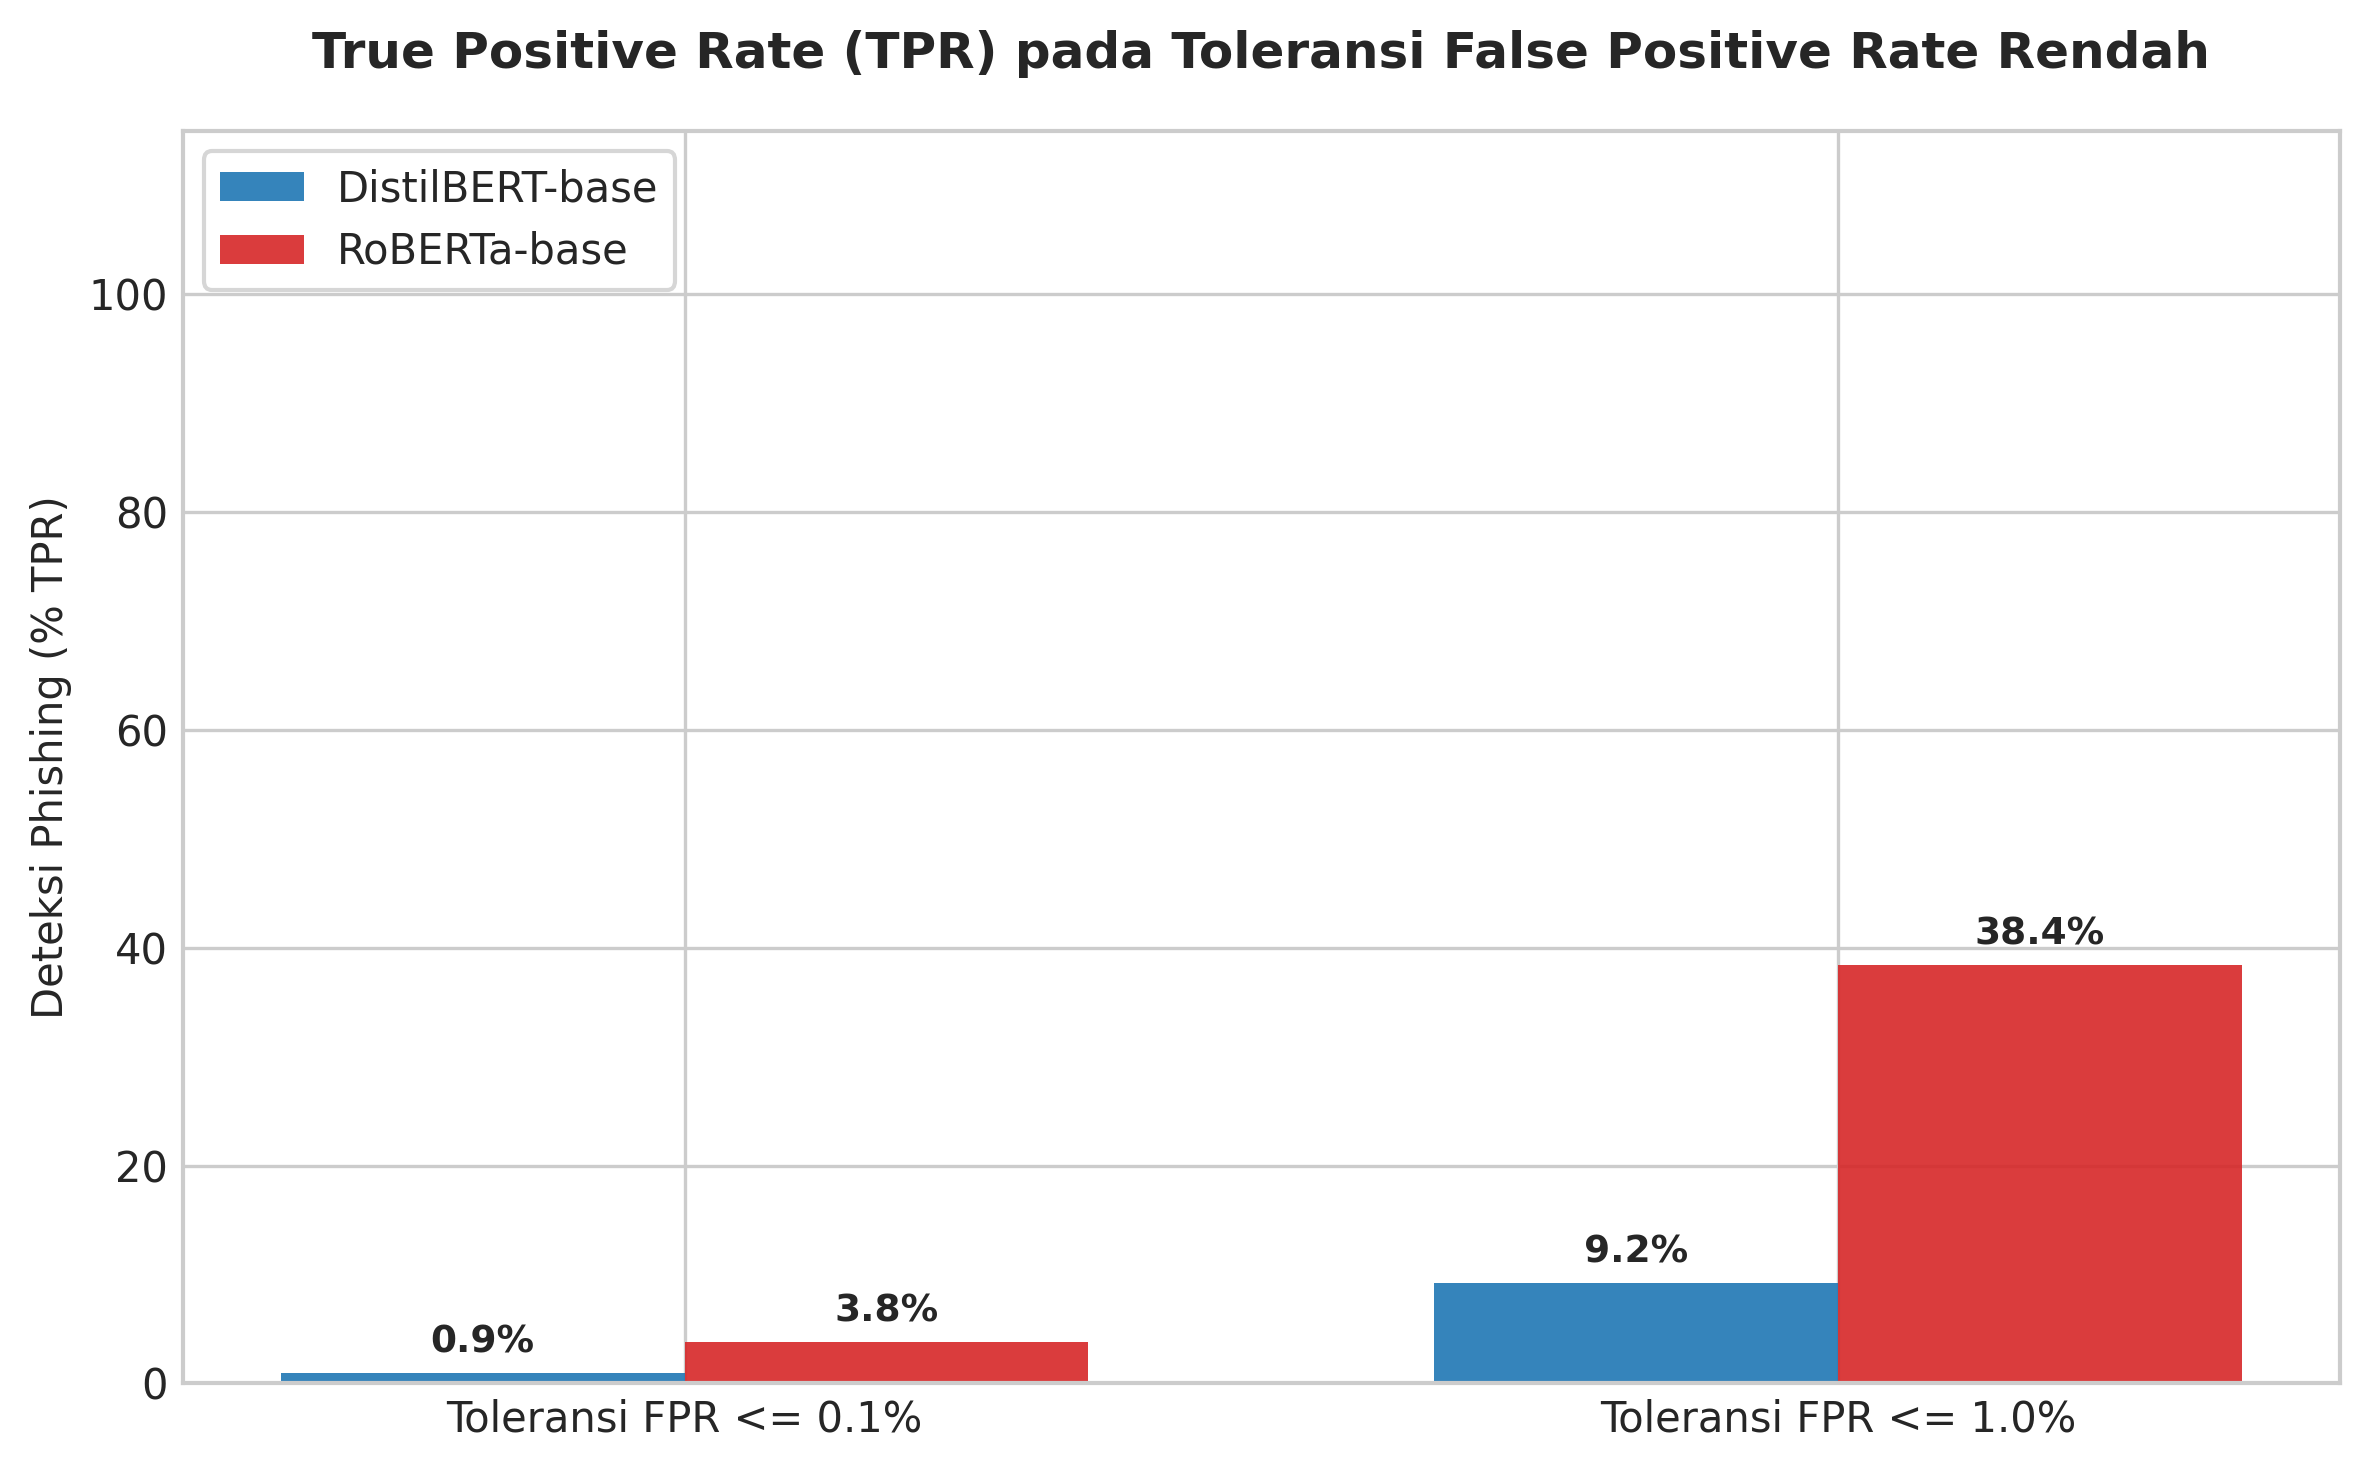

✅ Tersimpan: /content/drive/MyDrive/Skripsi/results/04_tpr_at_low_fpr_bars.png


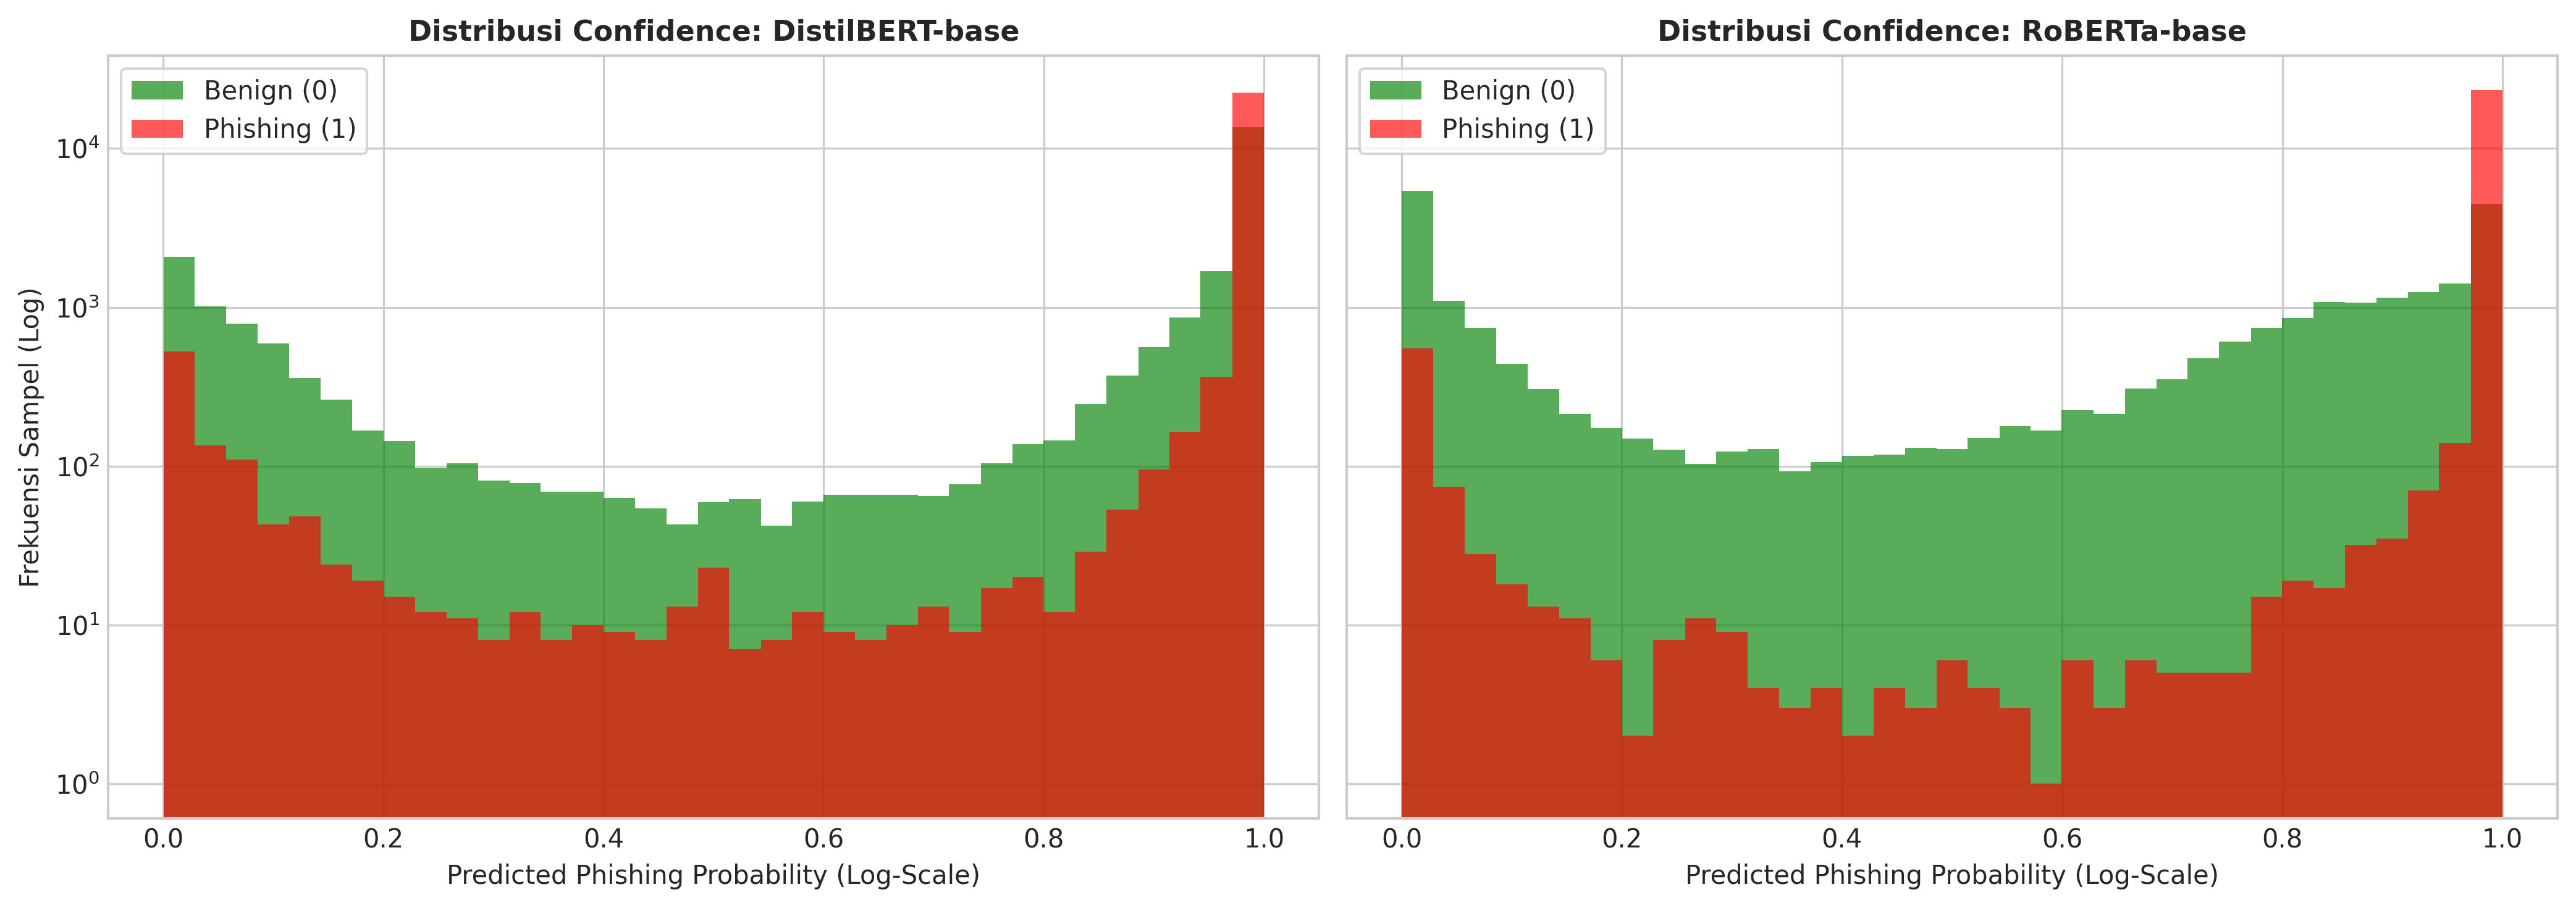

✅ Tersimpan: /content/drive/MyDrive/Skripsi/results/05_confidence_distribution.png


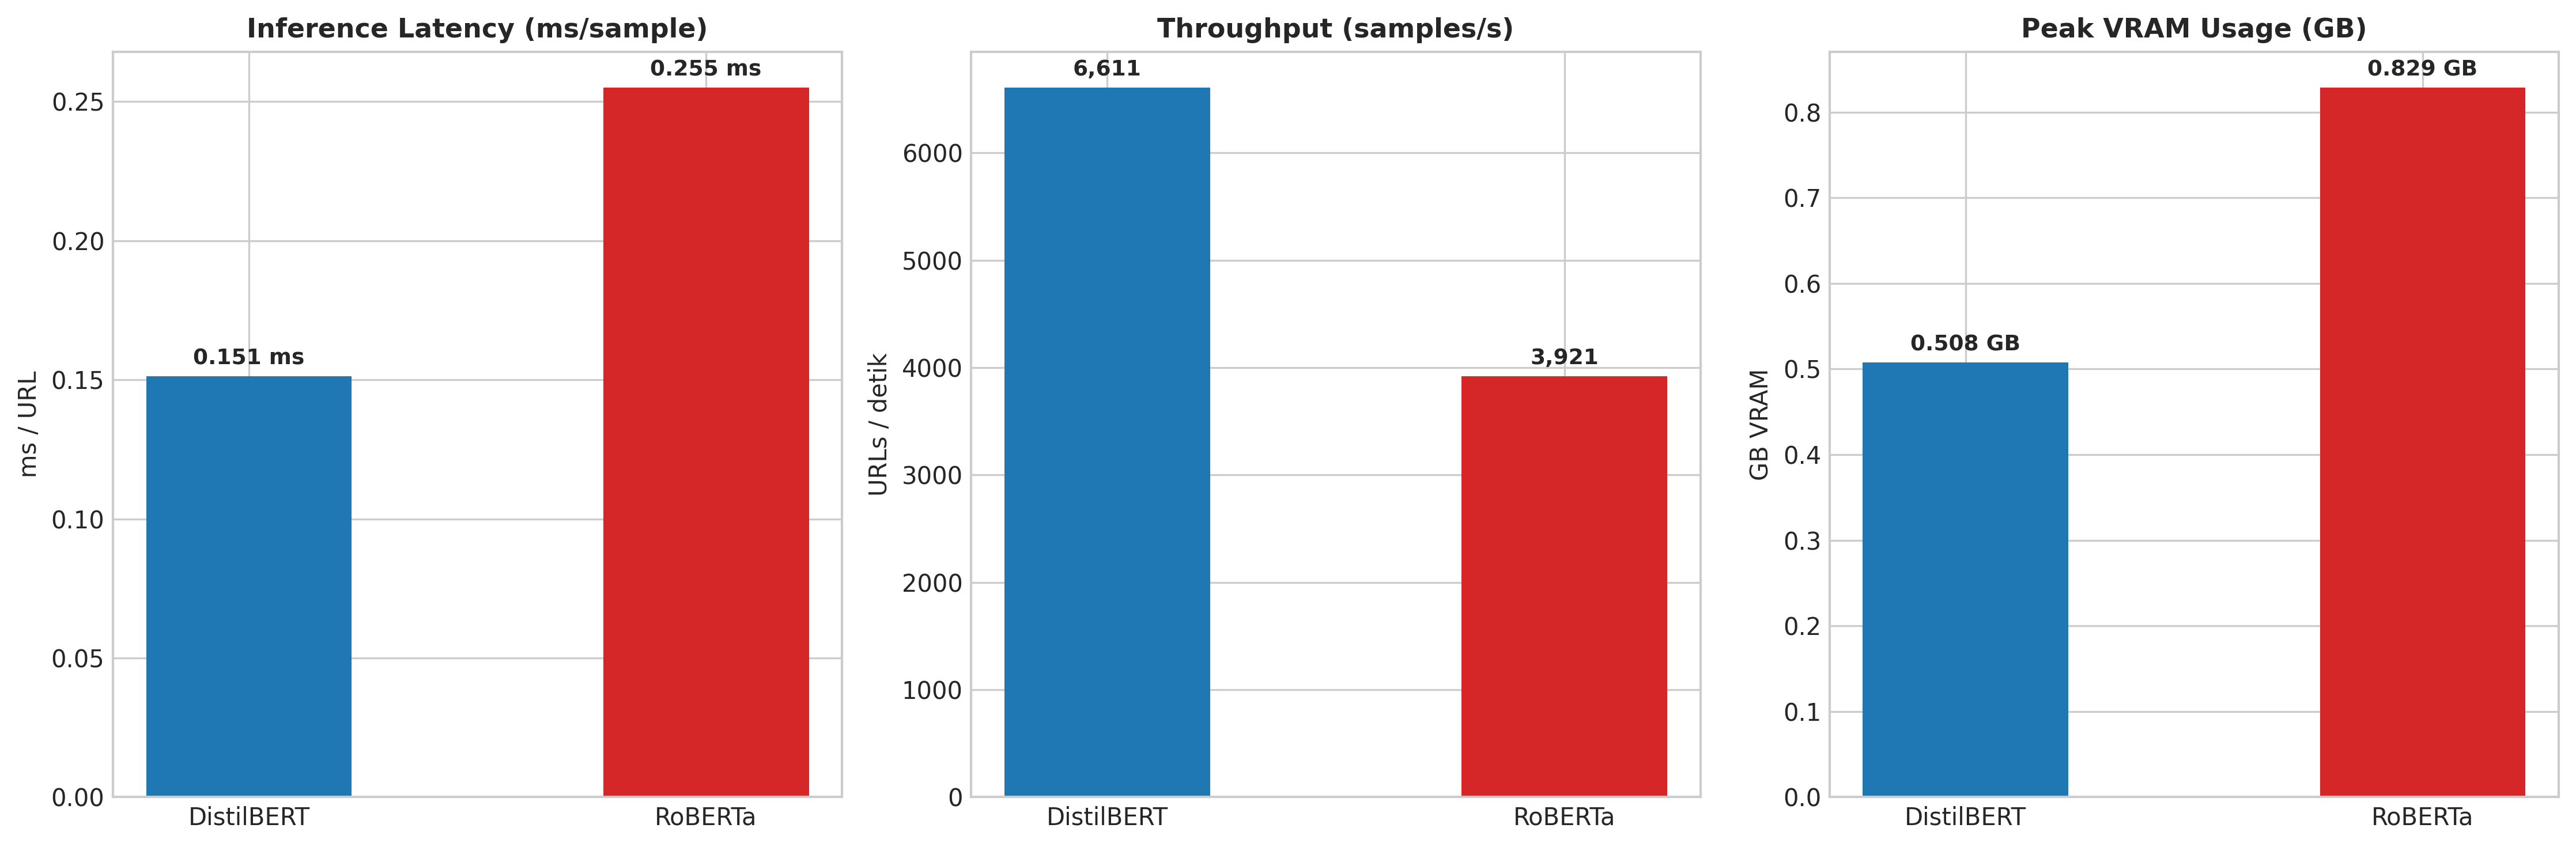

✅ Tersimpan: /content/drive/MyDrive/Skripsi/results/06_efficiency_comparison.png


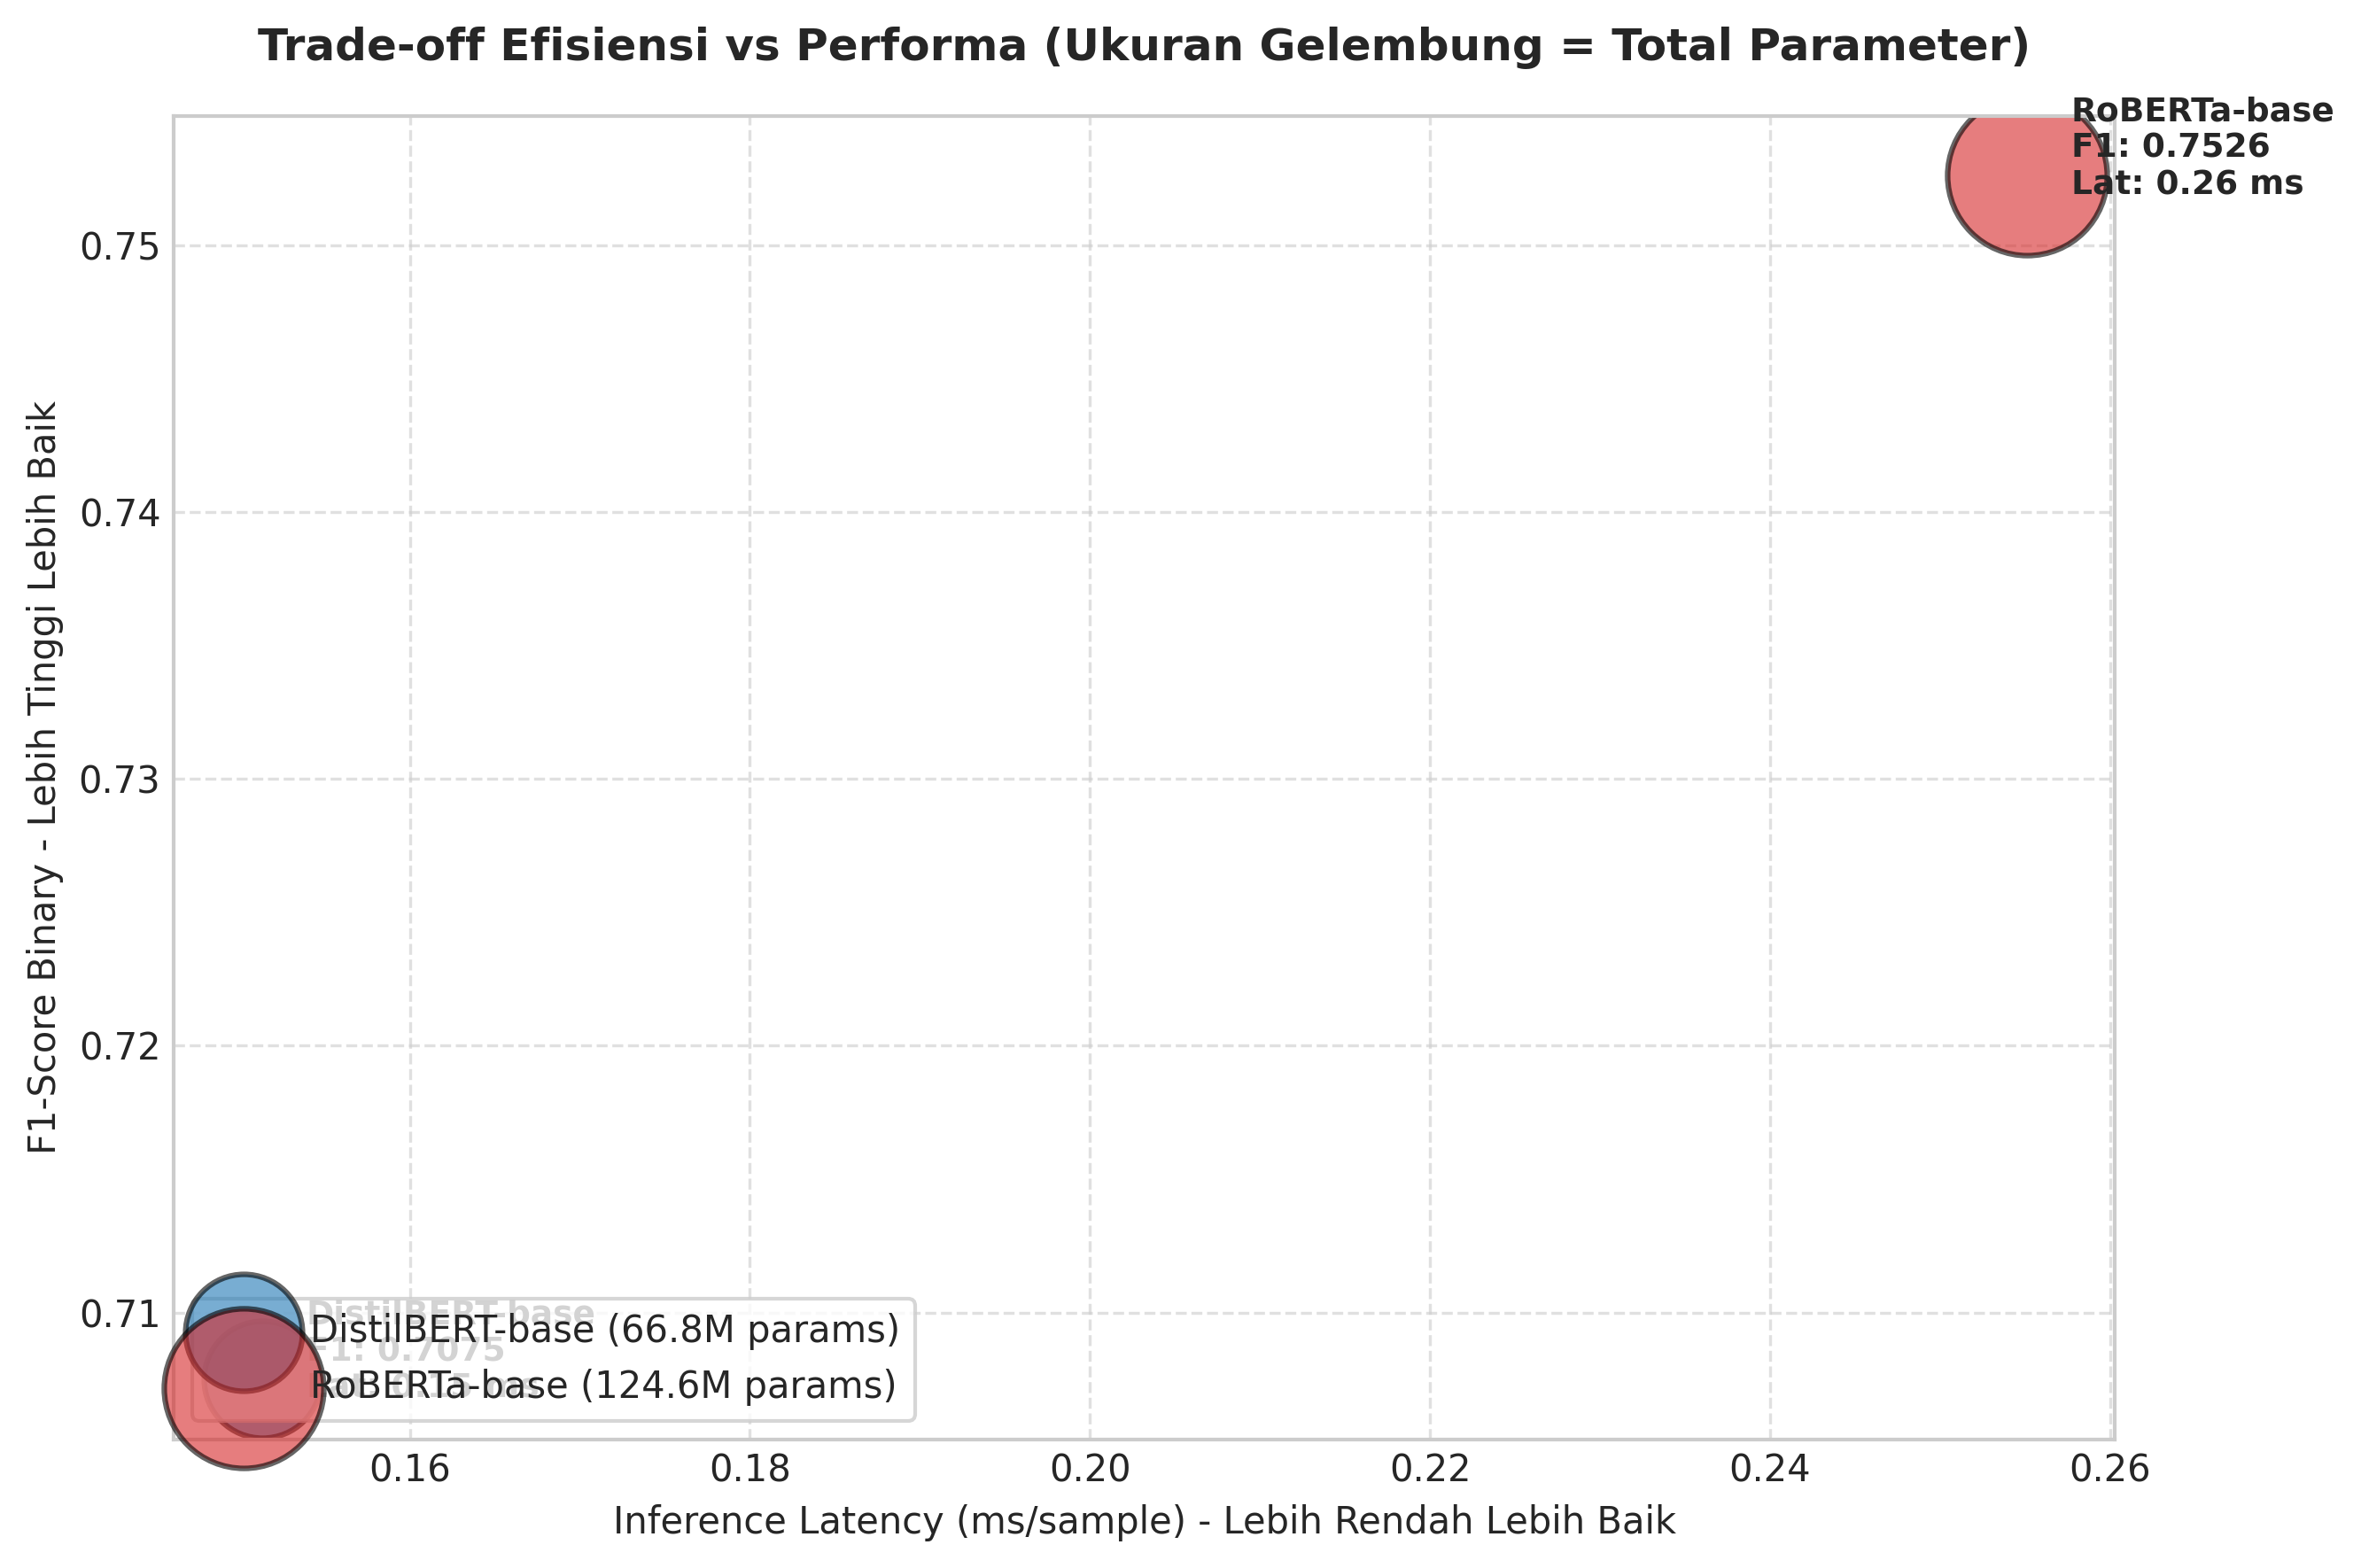

✅ Tersimpan: /content/drive/MyDrive/Skripsi/results/07_tradeoff_bubble_plot.png


In [6]:
print("[INFO] Membuat 7 visualisasi evaluasi 300 DPI di folder results...")

# --- 1. Confusion Matrices Berdampingan (01_confusion_matrices.png) ---
fig, axes = plt.subplots(1, 2, figsize=(13, 5), dpi=300)
for idx, m in enumerate(models_eval):
    cm = m['confusion_matrix']
    cm_pct = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100
    labels_annot = np.array([
        [f"{cm[0,0]:,}\n({cm_pct[0,0]:.1f}%)", f"{cm[0,1]:,}\n({cm_pct[0,1]:.1f}%)"],
        [f"{cm[1,0]:,}\n({cm_pct[1,0]:.1f}%)", f"{cm[1,1]:,}\n({cm_pct[1,1]:.1f}%)"]
    ])
    sns.heatmap(cm, annot=labels_annot, fmt='', cmap="Blues" if idx==0 else "Reds",
                ax=axes[idx], cbar=False, annot_kws={"size": 11, "weight": "bold"})
    axes[idx].set_title(f"Confusion Matrix: {m['model']}", fontsize=12, weight='bold', pad=10)
    axes[idx].set_xlabel("Prediksi Kelas", fontsize=10)
    axes[idx].set_ylabel("Label Sebenarnya", fontsize=10)
    axes[idx].set_xticklabels(['Benign (0)', 'Phishing (1)'])
    axes[idx].set_yticklabels(['Benign (0)', 'Phishing (1)'])

plt.tight_layout()
p1 = os.path.join(RESULTS_DIR, "01_confusion_matrices.png")
plt.savefig(p1, dpi=300)
plt.show()
print(f"✅ Tersimpan: {p1}")

# --- 2. Bar Chart Perbandingan 7 Metrik Performa (02_performance_metrics_bars.png) ---
metrics_keys = ['accuracy', 'precision', 'recall', 'f1_binary', 'f1_macro', 'roc_auc', 'pr_auc']
metrics_disp = ['Accuracy', 'Precision', 'Recall', 'F1-Binary', 'F1-Macro', 'ROC-AUC', 'PR-AUC']
x = np.arange(len(metrics_keys))
width = 0.35

fig, ax = plt.subplots(figsize=(13, 6), dpi=300)
rects1 = ax.bar(x - width/2, [distil_results[k] for k in metrics_keys], width, label='DistilBERT-base', color='#1f77b4', alpha=0.9)
rects2 = ax.bar(x + width/2, [roberta_results[k] for k in metrics_keys], width, label='RoBERTa-base', color='#d62728', alpha=0.9)

ax.set_title("Perbandingan Metrik Kinerja Klasifikasi pada Dataset Eksternal (OOD)", fontsize=13, weight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(metrics_disp, fontsize=10)
ax.set_ylim(0, 1.15)
ax.set_ylabel("Nilai Skor (0 - 1.0)", fontsize=11)
ax.legend(frameon=True, loc='lower right')

for rects in [rects1, rects2]:
    for rect in rects:
        h = rect.get_height()
        ax.annotate(f"{h:.3f}", xy=(rect.get_x() + rect.get_width() / 2, h),
                    xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=8, weight='semibold')

plt.tight_layout()
p2 = os.path.join(RESULTS_DIR, "02_performance_metrics_bars.png")
plt.savefig(p2, dpi=300)
plt.show()
print(f"✅ Tersimpan: {p2}")

# --- 3. Kurva ROC dan PR Berdampingan (03_roc_and_pr_curves.png) ---
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(14, 6), dpi=300)
colors_map = {'DistilBERT-base': '#1f77b4', 'RoBERTa-base': '#d62728'}

for m in models_eval:
    fpr, tpr, _ = roc_curve(m['y_true'], m['y_prob'])
    prec_vals, rec_vals, _ = precision_recall_curve(m['y_true'], m['y_prob'])
    c = colors_map[m['model']]
    ax_roc.plot(fpr, tpr, color=c, lw=2.2, label=f"{m['model']} (AUC = {m['roc_auc']:.4f})")
    ax_pr.plot(rec_vals, prec_vals, color=c, lw=2.2, label=f"{m['model']} (PR-AUC = {m['pr_auc']:.4f})")

ax_roc.plot([0, 1], [0, 1], 'k--', lw=1.2, label='Random Chance')
ax_roc.set_title("Receiver Operating Characteristic (ROC) Curve", fontsize=12, weight='bold')
ax_roc.set_xlabel("False Positive Rate (FPR)", fontsize=10)
ax_roc.set_ylabel("True Positive Rate (TPR)", fontsize=10)
ax_roc.legend(loc='lower right', frameon=True)
ax_roc.set_xlim([0.0, 1.0])
ax_roc.set_ylim([0.0, 1.02])

ax_pr.set_title("Precision-Recall (PR) Curve", fontsize=12, weight='bold')
ax_pr.set_xlabel("Recall", fontsize=10)
ax_pr.set_ylabel("Precision", fontsize=10)
ax_pr.legend(loc='lower left', frameon=True)
ax_pr.set_xlim([0.0, 1.0])
ax_pr.set_ylim([0.0, 1.02])

plt.tight_layout()
p3 = os.path.join(RESULTS_DIR, "03_roc_and_pr_curves.png")
plt.savefig(p3, dpi=300)
plt.show()
print(f"✅ Tersimpan: {p3}")

# --- 4. Bar Chart Deteksi Phishing pada FPR Rendah (04_tpr_at_low_fpr_bars.png) ---
fig, ax = plt.subplots(figsize=(8, 5), dpi=300)
fpr_names = ['Toleransi FPR <= 0.1%', 'Toleransi FPR <= 1.0%']
x_fpr = np.arange(2)
w_fpr = 0.35

d_tpr = [distil_results['tpr_at_fpr_0.1pct'] * 100, distil_results['tpr_at_fpr_1.0pct'] * 100]
r_tpr = [roberta_results['tpr_at_fpr_0.1pct'] * 100, roberta_results['tpr_at_fpr_1.0pct'] * 100]

r1 = ax.bar(x_fpr - w_fpr/2, d_tpr, w_fpr, label='DistilBERT-base', color='#1f77b4', alpha=0.9)
r2 = ax.bar(x_fpr + w_fpr/2, r_tpr, w_fpr, label='RoBERTa-base', color='#d62728', alpha=0.9)

ax.set_title("True Positive Rate (TPR) pada Toleransi False Positive Rate Rendah", fontsize=12, weight='bold', pad=15)
ax.set_xticks(x_fpr)
ax.set_xticklabels(fpr_names, fontsize=10)
ax.set_ylim(0, 115)
ax.set_ylabel("Deteksi Phishing (% TPR)", fontsize=10)
ax.legend(frameon=True, loc='upper left')

for rects in [r1, r2]:
    for rect in rects:
        h = rect.get_height()
        ax.annotate(f"{h:.1f}%", xy=(rect.get_x() + rect.get_width() / 2, h),
                    xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9, weight='bold')

plt.tight_layout()
p4 = os.path.join(RESULTS_DIR, "04_tpr_at_low_fpr_bars.png")
plt.savefig(p4, dpi=300)
plt.show()
print(f"✅ Tersimpan: {p4}")

# --- 5. Histogram Distribusi Probabilitas Prediksi (05_confidence_distribution.png) ---
fig, (ax_d, ax_r) = plt.subplots(1, 2, figsize=(14, 5), dpi=300, sharey=True)

for ax, m, c in zip([ax_d, ax_r], models_eval, ['#1f77b4', '#d62728']):
    y_prob = m['y_prob']
    y_true = m['y_true']
    ax.hist(y_prob[y_true == 0], bins=35, alpha=0.65, label='Benign (0)', color='green', log=True)
    ax.hist(y_prob[y_true == 1], bins=35, alpha=0.65, label='Phishing (1)', color='red', log=True)
    ax.set_title(f"Distribusi Confidence: {m['model']}", fontsize=11, weight='bold')
    ax.set_xlabel("Predicted Phishing Probability (Log-Scale)", fontsize=10)
    ax.legend(frameon=True)

ax_d.set_ylabel("Frekuensi Sampel (Log)", fontsize=10)
plt.tight_layout()
p5 = os.path.join(RESULTS_DIR, "05_confidence_distribution.png")
plt.savefig(p5, dpi=300)
plt.show()
print(f"✅ Tersimpan: {p5}")

# --- 6. Bar Chart Efisiensi Komputasi (06_efficiency_comparison.png) ---
fig, (ax_lat, ax_thr, ax_vram) = plt.subplots(1, 3, figsize=(15, 5), dpi=300)
m_labels = ['DistilBERT', 'RoBERTa']
colors_list = ['#1f77b4', '#d62728']

# Latency
lat_vals = [distil_results['latency_ms'], roberta_results['latency_ms']]
b1 = ax_lat.bar(m_labels, lat_vals, color=colors_list, width=0.45)
ax_lat.set_title("Inference Latency (ms/sample)", fontsize=11, weight='bold')
ax_lat.set_ylabel("ms / URL", fontsize=10)
for p in b1:
    h = p.get_height()
    ax_lat.annotate(f"{h:.3f} ms", xy=(p.get_x() + p.get_width() / 2, h),
                    xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9, weight='bold')

# Throughput
thr_vals = [distil_results['throughput_sps'], roberta_results['throughput_sps']]
b2 = ax_thr.bar(m_labels, thr_vals, color=colors_list, width=0.45)
ax_thr.set_title("Throughput (samples/s)", fontsize=11, weight='bold')
ax_thr.set_ylabel("URLs / detik", fontsize=10)
for p in b2:
    h = p.get_height()
    ax_thr.annotate(f"{h:,.0f}", xy=(p.get_x() + p.get_width() / 2, h),
                    xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9, weight='bold')

# Peak VRAM
vram_vals = [distil_results['peak_vram_gb'], roberta_results['peak_vram_gb']]
b3 = ax_vram.bar(m_labels, vram_vals, color=colors_list, width=0.45)
ax_vram.set_title("Peak VRAM Usage (GB)", fontsize=11, weight='bold')
ax_vram.set_ylabel("GB VRAM", fontsize=10)
for p in b3:
    h = p.get_height()
    ax_vram.annotate(f"{h:.3f} GB", xy=(p.get_x() + p.get_width() / 2, h),
                    xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9, weight='bold')

plt.tight_layout()
p6 = os.path.join(RESULTS_DIR, "06_efficiency_comparison.png")
plt.savefig(p6, dpi=300)
plt.show()
print(f"✅ Tersimpan: {p6}")

# --- 7. Trade-off Bubble Plot (07_tradeoff_bubble_plot.png) ---
fig, ax = plt.subplots(figsize=(9, 6), dpi=300)

for m, color in zip(models_eval, ['#1f77b4', '#d62728']):
    # Radius gelembung proporsional terhadap total parameter
    bubble_size = (m['total_params'] / 1e6) * 15
    ax.scatter(m['latency_ms'], m['f1_binary'], s=bubble_size, color=color, alpha=0.6, edgecolors='black', linewidth=1.5, label=f"{m['model']} ({m['total_params']/1e6:.1f}M params)")
    ax.annotate(f"{m['model']}\nF1: {m['f1_binary']:.4f}\nLat: {m['latency_ms']:.2f} ms",
                xy=(m['latency_ms'], m['f1_binary']), xytext=(12, -5), textcoords='offset points', fontsize=9, weight='bold')

ax.set_title("Trade-off Efisiensi vs Performa (Ukuran Gelembung = Total Parameter)", fontsize=12, weight='bold', pad=15)
ax.set_xlabel("Inference Latency (ms/sample) - Lebih Rendah Lebih Baik", fontsize=10)
ax.set_ylabel("F1-Score Binary - Lebih Tinggi Lebih Baik", fontsize=10)
ax.grid(True, linestyle='--', alpha=0.6)
ax.legend(frameon=True, loc='lower left')

plt.tight_layout()
p7 = os.path.join(RESULTS_DIR, "07_tradeoff_bubble_plot.png")
plt.savefig(p7, dpi=300)
plt.show()
print(f"✅ Tersimpan: {p7}")


## 7. Error Analysis: 5 False Positives & 5 False Negatives
Mengekstraksi 5 sampel representatif False Positive (FP: Benign diprediksi Phishing) dan False Negative (FN: Phishing lolos diprediksi Benign) untuk masing-masing model beserta probabilitas prediksinya.


In [7]:
print("======================================================================")
print("🔍 ERROR ANALYSIS: FALSE POSITIVES (FP) & FALSE NEGATIVES (FN)")
print("======================================================================")

analysis_records = []

for m in models_eval:
    m_name = m['model']
    y_true = m['y_true']
    y_pred = m['y_pred']
    y_prob = m['y_prob']
    urls = ext_df['url'].values

    # Indeks FP (True = 0, Pred = 1)
    fp_indices = np.where((y_true == 0) & (y_pred == 1))[0]
    # Urutkan berdasarkan confidence tertinggi untuk FP yang paling parah
    sorted_fp = fp_indices[np.argsort(-y_prob[fp_indices])][:5]

    # Indeks FN (True = 1, Pred = 0)
    fn_indices = np.where((y_true == 1) & (y_pred == 0))[0]
    # Urutkan berdasarkan confidence phishing terendah (paling yakin aman)
    sorted_fn = fn_indices[np.argsort(y_prob[fn_indices])][:5]

    print(f"\n--- Model: {m_name} ---")
    print("📌 5 Sampel False Positive Teratas (URL Aman terdeteksi Phishing):")
    for i, idx_fp in enumerate(sorted_fp, 1):
        u = urls[idx_fp]
        prob = y_prob[idx_fp]
        print(f"   [{i}] Prob Phishing: {prob:.4f} | URL: {u[:90]}")
        analysis_records.append({'Model': m_name, 'Error_Type': 'False Positive', 'Prob_Phishing': prob, 'URL': u})

    print("\n📌 5 Sampel False Negative Teratas (URL Phishing lolos terdeteksi Aman):")
    for i, idx_fn in enumerate(sorted_fn, 1):
        u = urls[idx_fn]
        prob = y_prob[idx_fn]
        print(f"   [{i}] Prob Phishing: {prob:.4f} | URL: {u[:90]}")
        analysis_records.append({'Model': m_name, 'Error_Type': 'False Negative', 'Prob_Phishing': prob, 'URL': u})

df_error_analysis = pd.DataFrame(analysis_records)
error_csv_path = os.path.join(RESULTS_DIR, "error_analysis_samples.csv")
df_error_analysis.to_csv(error_csv_path, index=False)
print(f"\n✅ Tabel Error Analysis tersimpan ke: {error_csv_path}")


🔍 ERROR ANALYSIS: FALSE POSITIVES (FP) & FALSE NEGATIVES (FN)

--- Model: DistilBERT-base ---
📌 5 Sampel False Positive Teratas (URL Aman terdeteksi Phishing):
   [1] Prob Phishing: 1.0000 | URL: https://domainparkingserver.net
   [2] Prob Phishing: 1.0000 | URL: https://pixelswhirl.com
   [3] Prob Phishing: 1.0000 | URL: https://ostrovok.ru
   [4] Prob Phishing: 1.0000 | URL: https://ibytedtos.com
   [5] Prob Phishing: 1.0000 | URL: https://dalyfeds.com

📌 5 Sampel False Negative Teratas (URL Phishing lolos terdeteksi Aman):
   [1] Prob Phishing: 0.0002 | URL: https://github.com/gstatic-kh5q6ekh/cdn-113-cloud/releases/download/static/id-owf836aos
   [2] Prob Phishing: 0.0002 | URL: https://github.com/tgak1s/Monotone-HWID-Spoofer/raw/refs/heads/main/Monotone.exe
   [3] Prob Phishing: 0.0002 | URL: https://github.com/mr441/szedo_harvestzones/releases/download/v1.0.5/szedo_harvestzones.v1
   [4] Prob Phishing: 0.0002 | URL: https://github.com/playyas/Monotone-HWID-Spoofer/raw/refs/heads/

## 8. Pencatatan Ringkasan Evaluasi ke Logbook Skripsi (`SKRIPSI_LOG.md`)
Menambahkan (append) seluruh hasil evaluasi OOD eksternal dan perbandingan efisiensi model secara permanen ke file dokumentasi riset.


In [8]:
print(f"[INFO] Mencatat ringkasan ke file logbook: {LOG_FILE}...")

current_time_str = time.strftime("%Y-%m-%d %H:%M:%S", time.localtime())

markdown_log_entry = f'''

---
### 🛡️ Catatan Evaluasi Out-of-Distribution (OOD) Dataset Eksternal ({current_time_str})
**Dataset Uji**: `/content/drive/MyDrive/Skripsi/data/external/phishing_url_dataset_unique.csv` ({len(ext_df):,} sampel URL biner bersih).

| Metrik Evaluasi | DistilBERT-base | RoBERTa-base | Keterangan / Analisis Industri |
| :--- | :---: | :---: | :--- |
| **Accuracy** | {distil_results['accuracy']*100:.2f}% | {roberta_results['accuracy']*100:.2f}% | Ketepatan klasifikasi total pada data OOD |
| **Precision** | {distil_results['precision']:.4f} | {roberta_results['precision']:.4f} | Rasio kebenaran alarm phishing |
| **Recall / Sensitivity** | {distil_results['recall']:.4f} | {roberta_results['recall']:.4f} | Cakupan penangkapan URL phishing riil |
| **F1-Score (Binary)** | {distil_results['f1_binary']:.4f} | {roberta_results['f1_binary']:.4f} | Rata-rata harmonik Precision & Recall |
| **F1-Score (Macro)** | {distil_results['f1_macro']:.4f} | {roberta_results['f1_macro']:.4f} | Keseimbangan performa kedua kelas |
| **ROC-AUC** | {distil_results['roc_auc']:.4f} | {roberta_results['roc_auc']:.4f} | Kemampuan pemisahan distribusi probabilitas |
| **PR-AUC** | {distil_results['pr_auc']:.4f} | {roberta_results['pr_auc']:.4f} | Luas area kurva Precision-Recall |
| **TPR @ FPR ≤ 0.1%** | **{distil_results['tpr_at_fpr_0.1pct']*100:.2f}%** | **{roberta_results['tpr_at_fpr_0.1pct']*100:.2f}%** | Metrik Keamanan Siber: Deteksi Phishing saat False Alarm ≤ 1 per 1000 |
| **TPR @ FPR ≤ 1.0%** | **{distil_results['tpr_at_fpr_1.0pct']*100:.2f}%** | **{roberta_results['tpr_at_fpr_1.0pct']*100:.2f}%** | Deteksi Phishing saat False Alarm ≤ 1 per 100 |
| **Inference Latency** | **{distil_results['latency_ms']:.3f} ms** | **{roberta_results['latency_ms']:.3f} ms** | Waktu inferensi per sampel URL |
| **Throughput** | **{distil_results['throughput_sps']:,.0f} URLs/s** | **{roberta_results['throughput_sps']:,.0f} URLs/s** | Throughput batch inferensi GPU |
| **Peak VRAM** | **{distil_results['peak_vram_gb']:.3f} GB** | **{roberta_results['peak_vram_gb']:.3f} GB** | Konsumsi memori GPU saat inferensi |
| **Total Parameters** | {distil_results['total_params']:,} | {roberta_results['total_params']:,} | Ukuran bobot arsitektur model |

*File grafik hasil 300 DPI tersimpan di `/content/drive/MyDrive/Skripsi/results/`.*
'''

try:
    with open(LOG_FILE, "a", encoding="utf-8") as f:
        f.write(markdown_log_entry)
    print(f"✅ [SUKSES] Berhasil mencatat entri evaluasi ke: {LOG_FILE}")
except Exception as e:
    print(f"⚠️ Gagal menulis ke logbook: {e}")

# Ekspor tabel hasil evaluasi ke CSV
final_ext_csv = os.path.join(RESULTS_DIR, "final_ood_evaluation_results.csv")
df_comparison.to_csv(final_ext_csv, index=False)
print(f"✅ Ringkasan CSV tersimpan ke: {final_ext_csv}")

print("\n🚀 [SELESAI] File 5: 05_Evaluasi_OOD.ipynb berhasil dieksekusi dengan sempurna!")


[INFO] Mencatat ringkasan ke file logbook: /content/drive/MyDrive/Skripsi/SKRIPSI_LOG.md...
✅ [SUKSES] Berhasil mencatat entri evaluasi ke: /content/drive/MyDrive/Skripsi/SKRIPSI_LOG.md
✅ Ringkasan CSV tersimpan ke: /content/drive/MyDrive/Skripsi/results/final_ood_evaluation_results.csv

🚀 [SELESAI] File 5: 05_Evaluasi_OOD.ipynb berhasil dieksekusi dengan sempurna!
